# Retail Sales Analysis — Exploratory Data Analysis

## Project Overview

This project explores retail transaction data to understand sales performance, profitability, customer purchasing behavior, product performance, discount patterns, geographic performance, and shipping trends.

Python, Pandas, NumPy, and Matplotlib are used to inspect the dataset, calculate business metrics, investigate potential profitability issues, and communicate findings through tables and charts.

## Business Objectives

1. Evaluate overall sales, profit, and profit margin.
2. Compare category and sub-category performance.
3. Analyze regional and state/province performance.
4. Understand customer value, order frequency, and average order value.
5. Investigate discount levels and their relationship with profitability.
6. Analyze monthly and yearly sales and profit trends.
7. Compare shipping modes using sales, profit, order volume, and average order value.
8. Identify loss-making transactions and areas for further investigation.

## Dataset Description

- **Dataset:** Sample Superstore
- **Records:** 10,194 transaction-line records
- **Columns:** 21
- **Order-date range in the file:** January 3, 2023 – December 30, 2026
- **Source file:** `sample_-_superstore.xls`

Each row represents a product line within an order. Therefore, repeated Order IDs are expected; order counts are calculated using unique Order IDs.

## Tools and Technologies

- Python
- Pandas
- NumPy
- Matplotlib
- Google Colab

## Project Workflow

1. Load and inspect the dataset.
2. Assess data quality and data types.
3. Calculate overall business KPIs.
4. Analyze category, region, segment, sub-category, discount, customer, product, state, and shipping performance.
5. Analyze monthly and yearly trends.
6. Investigate loss-making transactions and date quality.
7. Validate key aggregations and summarize business findings.

## Dataset and Reproducibility Note

The source file must be available in the Colab session before the Excel-loading cell runs. When prompted by the upload cell, select `sample_-_superstore.xls`.

**Important limitation:** The dataset contains dates later than November 24, 2026. These records are retained as supplied, but future-dated observations must be considered when interpreting time-based results. This is a sample dataset, not verified live business data.


## 1. Import Libraries and Load the Dataset

In [1]:
import pandas as pd
import numpy as np

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
from google.colab import files

uploaded = files.upload()

Saving sample_-_superstore.xls to sample_-_superstore.xls


In [3]:
df = pd.read_excel("sample_-_superstore.xls")

print("Dataset loaded successfully!")

Dataset loaded successfully!


## 2. Load and Explore the Dataset

In [4]:
df.shape

(10194, 21)

In [5]:
df.columns

Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'Country/Region', 'City',
       'State/Province', 'Postal Code', 'Region', 'Product ID', 'Category',
       'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount',
       'Profit'],
      dtype='object')

In [6]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,US-2023-103800,2023-01-03,2023-01-07,Standard Class,DP-13000,Darren Powers,Consumer,United States,Houston,...,77095,Central,OFF-PA-10000174,Office Supplies,Paper,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.448,2,0.2,5.5512
1,2,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-BI-10004094,Office Supplies,Binders,GBC Standard Plastic Binding Systems Combs,3.540,2,0.8,-5.4870
2,3,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-LA-10003223,Office Supplies,Labels,Avery 508,11.784,3,0.2,4.2717
3,4,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-ST-10002743,Office Supplies,Storage,SAFCO Boltless Steel Shelving,272.736,3,0.2,-64.7748
4,5,US-2023-141817,2023-01-05,2023-01-12,Standard Class,MB-18085,Mick Brown,Consumer,United States,Philadelphia,...,19143,East,OFF-AR-10003478,Office Supplies,Art,Avery Hi-Liter EverBold Pen Style Fluorescent ...,19.536,3,0.2,4.8840


In [7]:
df.dtypes

,0
Row ID,int64
Order ID,object
Order Date,datetime64[ns]
Ship Date,datetime64[ns]
Ship Mode,object
Customer ID,object
Customer Name,object
Segment,object
Country/Region,object
City,object


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10194 entries, 0 to 10193
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Row ID          10194 non-null  int64         
 1   Order ID        10194 non-null  object        
 2   Order Date      10194 non-null  datetime64[ns]
 3   Ship Date       10194 non-null  datetime64[ns]
 4   Ship Mode       10194 non-null  object        
 5   Customer ID     10194 non-null  object        
 6   Customer Name   10194 non-null  object        
 7   Segment         10194 non-null  object        
 8   Country/Region  10194 non-null  object        
 9   City            10194 non-null  object        
 10  State/Province  10194 non-null  object        
 11  Postal Code     10194 non-null  object        
 12  Region          10194 non-null  object        
 13  Product ID      10194 non-null  object        
 14  Category        10194 non-null  object        
 15  Su

## 3. Initial Data Quality Assessment

In [9]:
df.isnull().sum()

,0
Row ID,0
Order ID,0
Order Date,0
Ship Date,0
Ship Mode,0
Customer ID,0
Customer Name,0
Segment,0
Country/Region,0
City,0


In [10]:
df.duplicated().sum()

np.int64(0)

### Initial Data Quality Assessment

**Dataset size:** 10,194 rows and 21 columns.

**Observations:**

- The dataset contains retail order information, including customer, product, geographical, sales, quantity, discount, and profit information.
- Order Date and Ship Date are already recognized as datetime columns.
- Sales, Discount, and Profit are numeric columns.
- No missing values were detected across the dataset.
- No exact duplicate rows were detected using a full-row duplicate check.
- Multiple records can share the same Order ID because an order can contain multiple product lines.

**Initial conclusion:**

The dataset appears structurally suitable for further analysis based on the initial checks. Additional validation is required to identify unusual sales, negative profit, discount patterns, and other potential business-level data quality issues.

In [11]:
df["Order ID"].nunique()

5111

In [12]:
df["Customer ID"].nunique()

804

In [13]:
df["Sales"].sum()

np.float64(2326534.3543)

In [14]:
df["Profit"].sum()

np.float64(292296.8145999999)

In [15]:
df["Order Date"].min()

Timestamp('2023-01-03 00:00:00')

In [16]:
df["Order Date"].max()

Timestamp('2026-12-30 00:00:00')

## 4. Overall Business KPIs

In [17]:
total_orders = df["Order ID"].nunique()
total_customers = df["Customer ID"].nunique()
total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
profit_margin = (total_profit / total_sales) * 100

print("Total Orders:", total_orders)
print("Total Customers:", total_customers)
print("Total Sales:", round(total_sales, 2))
print("Total Profit:", round(total_profit, 2))
print("Profit Margin:", round(profit_margin, 2), "%")

Total Orders: 5111
Total Customers: 804
Total Sales: 2326534.35
Total Profit: 292296.81
Profit Margin: 12.56 %


## 5. Category Analysis

In [18]:
category_analysis = df.groupby("Category").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum")
)

print(category_analysis)

                 Total_Sales  Total_Profit  Total_Quantity
Category                                                  
Furniture        754747.7613    19729.9956            8369
Office Supplies  731893.3140   126023.4434           23268
Technology       839893.2790   146543.3756            7017


In [19]:
category_analysis.sort_values(
    by="Total_Sales",
    ascending=False
)

,Total_Sales,Total_Profit,Total_Quantity
Category,,,
Technology,839893.2790,146543.3756,7017
Furniture,754747.7613,19729.9956,8369
Office Supplies,731893.3140,126023.4434,23268


In [20]:
category_analysis["Profit_Margin"] = (
    category_analysis["Total_Profit"] / category_analysis["Total_Sales"]
) * 100

category_analysis.sort_values(
    by="Profit_Margin",
    ascending=False
)

,Total_Sales,Total_Profit,Total_Quantity,Profit_Margin
Category,,,,
Technology,839893.2790,146543.3756,7017,17.447857
Office Supplies,731893.3140,126023.4434,23268,17.218827
Furniture,754747.7613,19729.9956,8369,2.614118


### Category Sales and Profitability Analysis

**Key Findings**

- Technology is the highest-performing category, generating the highest sales (839,893.28) and profit (146,543.38), with a profit margin of 17.45%.
- Office Supplies generated the highest sales volume, with 23,268 units sold. It achieved a profit margin of 17.22%, indicating strong profitability.
- Furniture generated 754,747.76 in sales but only 19,729.99 in profit, resulting in a profit margin of 2.61%.
- Furniture's low profitability despite substantial sales indicates that further investigation into discounting, product costs, and subcategory performance is necessary.

**Business Recommendation**

Prioritize high-performing Technology products and evaluate Office Supplies opportunities to sustain profitability. Investigate Furniture products to identify the factors contributing to low margins and determine whether pricing, discount policies, or product mix adjustments are required.

## 6. Regional Analysis

In [21]:
region_analysis = df.groupby("Region").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum"),
    Total_Orders=("Order ID", "nunique")
)

region_analysis

,Total_Sales,Total_Profit,Total_Quantity,Total_Orders
Region,,,,
Central,503170.6728,39865.3070,8820,1179
East,691828.1680,94883.2603,11159,1475
South,391721.9050,46749.4303,6209,822
West,739813.6085,110798.8170,12466,1635


In [22]:
region_analysis.sort_values(
    by="Total_Sales",
    ascending=False
)

,Total_Sales,Total_Profit,Total_Quantity,Total_Orders
Region,,,,
West,739813.6085,110798.8170,12466,1635
East,691828.1680,94883.2603,11159,1475
Central,503170.6728,39865.3070,8820,1179
South,391721.9050,46749.4303,6209,822


In [23]:
region_analysis["Profit_Margin"] = (
    region_analysis["Total_Profit"] / region_analysis["Total_Sales"]
) * 100

region_analysis.sort_values(
    by="Profit_Margin",
    ascending=False
)

,Total_Sales,Total_Profit,Total_Quantity,Total_Orders,Profit_Margin
Region,,,,,
West,739813.6085,110798.8170,12466,1635,14.976585
East,691828.1680,94883.2603,11159,1475,13.714859
South,391721.9050,46749.4303,6209,822,11.934342
Central,503170.6728,39865.3070,8820,1179,7.922820


### Regional Sales and Profit Analysis

**Key Findings**

- West is the leading region, generating 739,813.61 in sales and 110,798.82 in profit, with 1,635 orders.
- East is the second-highest-performing region, generating 691,828.17 in sales and 94,883.26 in profit.
- Central generated 503,170.67 in sales but only 39,865.31 in profit, resulting in the lowest profit margin among the four regions.
- South generated lower sales than Central but achieved higher profit, indicating better profitability relative to its sales.

**Business Recommendation**

Maintain the strong performance of West and East while investigating Central's low profitability. Analyze discount patterns, product categories, and subcategory performance in Central to identify opportunities to improve margins.

## 7. Customer Segment Analysis

In [24]:
segment_analysis = df.groupby("Segment").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum"),
    Total_Orders=("Order ID", "nunique"),
    Unique_Customers=("Customer ID", "nunique")
)

segment_analysis

,Total_Sales,Total_Profit,Total_Quantity,Total_Orders,Unique_Customers
Segment,,,,,
Consumer,1.170660e+06,136371.4463,19844,2628,416
Corporate,7.158061e+05,94249.6400,11898,1552,239
Home Office,4.400684e+05,61675.7283,6912,931,149


In [25]:
segment_analysis.sort_values(
    by="Total_Sales",
    ascending=False
)

,Total_Sales,Total_Profit,Total_Quantity,Total_Orders,Unique_Customers
Segment,,,,,
Consumer,1.170660e+06,136371.4463,19844,2628,416
Corporate,7.158061e+05,94249.6400,11898,1552,239
Home Office,4.400684e+05,61675.7283,6912,931,149


In [26]:
segment_analysis["Profit_Margin"] = (
    segment_analysis["Total_Profit"] / segment_analysis["Total_Sales"]
) * 100

segment_analysis.sort_values(
    by="Profit_Margin",
    ascending=False
)

,Total_Sales,Total_Profit,Total_Quantity,Total_Orders,Unique_Customers,Profit_Margin
Segment,,,,,,
Home Office,4.400684e+05,61675.7283,6912,931,149,14.015031
Corporate,7.158061e+05,94249.6400,11898,1552,239,13.166923
Consumer,1.170660e+06,136371.4463,19844,2628,416,11.649110


### Customer Segment Analysis

**Key Findings**

- Consumer is the largest customer segment, generating approximately 1.17 million in sales, 136,371.45 in profit, and 19,844 units sold.
- Corporate customers generated 715,806.10 in sales and 94,249.64 in profit.
- Home Office is the smallest segment by total sales, but its profit margin is approximately 14.02%, higher than Consumer and Corporate.
- Consumer generates the largest overall contribution, while Home Office demonstrates stronger profitability relative to its sales.

**Business Recommendation**

Continue focusing on the Consumer segment because of its strong sales contribution, while exploring opportunities to increase sales among Home Office customers. Evaluate segment-specific purchasing behavior and product preferences to develop more targeted sales strategies.

## 8. Sub-Category Analysis

In [27]:
subcategory_analysis = df.groupby("Sub-Category").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum"),
    Total_Orders=("Order ID", "nunique")
)

subcategory_analysis

,Total_Sales,Total_Profit,Total_Quantity,Total_Orders
Sub-Category,,,,
Accessories,167380.3180,41936.6357,2976,718
Appliances,108213.1850,18329.4844,1750,459
Art,27659.0140,6653.1962,3092,756
Binders,207354.8810,31426.1003,6071,1339
Bookcases,115361.2043,-3632.0736,878,228
Chairs,335768.2490,27223.5323,2431,591
Copiers,150745.2900,56093.9365,242,70
Envelopes,16528.3620,6988.0247,914,251
Fasteners,8532.2400,2428.6358,980,226


In [28]:
subcategory_analysis.sort_values(
    by="Total_Profit",
    ascending=False
)


,Total_Sales,Total_Profit,Total_Quantity,Total_Orders
Sub-Category,,,,
Copiers,150745.2900,56093.9365,242,70
Phones,331842.6400,45050.8265,3357,826
Accessories,167380.3180,41936.6357,2976,718
Paper,79540.5380,34511.5070,5207,1205
Binders,207354.8810,31426.1003,6071,1339
Chairs,335768.2490,27223.5323,2431,591
Storage,224644.5540,21285.1115,3191,787
Appliances,108213.1850,18329.4844,1750,459
Furnishings,95598.1260,13891.7430,3799,919


In [29]:
subcategory_analysis["Profit_Margin"] = (
    subcategory_analysis["Total_Profit"] / subcategory_analysis["Total_Sales"]
) * 100

subcategory_analysis.sort_values(
    by="Profit_Margin",
    ascending=False
)

,Total_Sales,Total_Profit,Total_Quantity,Total_Orders,Profit_Margin
Sub-Category,,,,,
Labels,12695.0420,5572.7780,1410,348,43.897279
Paper,79540.5380,34511.5070,5207,1205,43.388576
Envelopes,16528.3620,6988.0247,914,251,42.278991
Copiers,150745.2900,56093.9365,242,70,37.211071
Fasteners,8532.2400,2428.6358,980,226,28.464223
Accessories,167380.3180,41936.6357,2976,718,25.054700
Art,27659.0140,6653.1962,3092,756,24.054351
Appliances,108213.1850,18329.4844,1750,459,16.938310
Binders,207354.8810,31426.1003,6071,1339,15.155708


### Sub-Category Sales and Profit Analysis

**Key Findings**

- Copiers generated the highest total profit of 56,093.94.
- Phones generated the highest sales of 331,842.64.
- Paper generated 34,511.51 in profit from 79,540.54 in sales, demonstrating strong profitability relative to its sales.
- Tables generated 208,020.18 in sales but incurred a loss of 17,753.21, making it the largest loss-making sub-category.
- Bookcases and Supplies also generated negative profits of 3,632.07 and 1,171.39, respectively.

**Business Recommendation**

Prioritize profitable sub-categories such as Copiers, Phones, Accessories, and Paper while investigating the negative profitability of Tables, Bookcases, and Supplies. Review discounting, pricing, and product costs before making decisions to expand or reduce sales in these sub-categories.

### Sub-Category Profit Margin Analysis

**Key Findings**

- Labels achieved the highest profit margin at 43.90%, followed by Paper at 43.39% and Envelopes at 42.28%.
- Copiers generated a profit margin of 37.21%, while Accessories achieved 25.05%.
- Tables had the lowest profit margin at -8.53%, followed by Bookcases at -3.15% and Supplies at -2.51%.
- High profit margin and high total profit are different measures. Labels had the highest margin, while Copiers generated the highest total profit.

**Business Recommendation**

Maintain the performance of high-margin sub-categories and investigate the negative margins of Tables, Bookcases, and Supplies. Further analysis of discount levels, product costs, and pricing is needed before recommending corrective actions.

## 9. Discount Analysis

In [30]:
discount_analysis = df.groupby("Discount").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum"),
    Total_Orders=("Order ID", "nunique")
)

discount_analysis

,Total_Sales,Total_Profit,Total_Quantity,Total_Orders
Discount,,,,
0.00,1.105324e+06,326718.5872,18770,2714
0.10,5.495250e+04,9099.9700,377,91
0.15,2.755852e+04,1418.9915,198,51
0.20,7.739394e+05,91079.9517,13856,2440
0.30,1.044741e+05,-10513.4456,855,214
0.32,1.449346e+04,-2391.1377,105,27
0.40,1.164978e+05,-23086.3742,789,186
0.45,5.484974e+03,-2493.1111,45,10
0.50,5.891854e+04,-20506.4281,241,64


In [31]:
discount_analysis["Profit_Margin"] = (
    discount_analysis["Total_Profit"] / discount_analysis["Total_Sales"]
) * 100

discount_analysis.sort_values(
    by="Discount",
    ascending=True
)

,Total_Sales,Total_Profit,Total_Quantity,Total_Orders,Profit_Margin
Discount,,,,,
0.00,1.105324e+06,326718.5872,18770,2714,29.558632
0.10,5.495250e+04,9099.9700,377,91,16.559702
0.15,2.755852e+04,1418.9915,198,51,5.149012
0.20,7.739394e+05,91079.9517,13856,2440,11.768357
0.30,1.044741e+05,-10513.4456,855,214,-10.063211
0.32,1.449346e+04,-2391.1377,105,27,-16.498047
0.40,1.164978e+05,-23086.3742,789,186,-19.817012
0.45,5.484974e+03,-2493.1111,45,10,-45.453472
0.50,5.891854e+04,-20506.4281,241,64,-34.804712


### Discount and Profitability Analysis

**Key Findings**

- Transactions with no discount generated 1,105,324.00 in sales and 326,718.59 in profit, achieving a profit margin of 29.56%.
- The 10% discount level achieved a profit margin of 16.56%, while the 15% discount level achieved only 5.15%.
- The 20% discount level remained profitable, generating 91,079.95 in profit with an 11.77% profit margin.
- Discount levels of 30% and above generated negative total profits in this dataset.
- The 80% discount level recorded the lowest profit margin at -180.01%, generating a loss of 30,565.27 against sales of 16,980.15.

**Business Recommendation**

Review discount policies, particularly discounts of 30% and above, which were associated with losses in this dataset. Evaluate discount levels alongside product categories, product costs, and customer purchasing behavior before implementing changes to pricing or discount strategies.

**Analytical Limitation**

The observed relationship between discount levels and profitability does not establish causation. Further analysis is required to determine the extent to which discounts contribute to losses.

## 10. Monthly Sales and Profit Trends

In [32]:
df["Order Month"] = df["Order Date"].dt.to_period("M")

df[["Order Date", "Order Month"]].head(10)

,Order Date,Order Month
0,2023-01-03,2023-01
1,2023-01-04,2023-01
2,2023-01-04,2023-01
3,2023-01-04,2023-01
4,2023-01-05,2023-01
5,2023-01-06,2023-01
6,2023-01-06,2023-01
7,2023-01-06,2023-01
8,2023-01-06,2023-01
9,2023-01-06,2023-01


In [33]:
monthly_analysis = df.groupby("Order Month").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Orders=("Order ID", "nunique"),
    Total_Quantity=("Quantity", "sum")
)

monthly_analysis

,Total_Sales,Total_Profit,Total_Orders,Total_Quantity
Order Month,,,,
2023-01,14518.0550,2539.3907,33,306
2023-02,4519.8920,862.3084,28,159
2023-03,56933.9090,693.4499,72,597
2023-04,28295.3450,3488.8352,66,536
2023-05,26319.7670,3196.3918,72,504
2023-06,34669.4796,4999.7594,67,524
2023-07,33946.3930,-841.4826,65,550
2023-08,28918.3385,5765.2250,75,624
2023-09,82670.4288,8593.6302,134,1015


In [34]:
monthly_analysis = monthly_analysis.sort_index()

monthly_analysis

,Total_Sales,Total_Profit,Total_Orders,Total_Quantity
Order Month,,,,
2023-01,14518.0550,2539.3907,33,306
2023-02,4519.8920,862.3084,28,159
2023-03,56933.9090,693.4499,72,597
2023-04,28295.3450,3488.8352,66,536
2023-05,26319.7670,3196.3918,72,504
2023-06,34669.4796,4999.7594,67,524
2023-07,33946.3930,-841.4826,65,550
2023-08,28918.3385,5765.2250,75,624
2023-09,82670.4288,8593.6302,134,1015


In [35]:
highest_sales_month = monthly_analysis["Total_Sales"].idxmax()
lowest_sales_month = monthly_analysis["Total_Sales"].idxmin()
highest_profit_month = monthly_analysis["Total_Profit"].idxmax()
lowest_profit_month = monthly_analysis["Total_Profit"].idxmin()

print("Highest Sales Month:")
print(highest_sales_month, monthly_analysis.loc[highest_sales_month, "Total_Sales"])

print("\nLowest Sales Month:")
print(lowest_sales_month, monthly_analysis.loc[lowest_sales_month, "Total_Sales"])

print("\nHighest Profit Month:")
print(highest_profit_month, monthly_analysis.loc[highest_profit_month, "Total_Profit"])

print("\nLowest Profit Month:")
print(lowest_profit_month, monthly_analysis.loc[lowest_profit_month, "Total_Profit"])

Highest Sales Month:
2026-11 118454.505

Lowest Sales Month:
2023-02 4519.892

Highest Profit Month:
2025-12 17926.3013

Lowest Profit Month:
2024-01 -3189.803000000001


### Monthly Sales and Profit Trend Analysis

**Key Findings**

- November 2026 recorded the highest monthly sales at 118,454.51.
- February 2023 recorded the lowest monthly sales at 4,519.89.
- December 2025 recorded the highest monthly profit at 17,926.30.
- Sales were relatively strong during September, November, and December across multiple years, suggesting a potential late-year sales pattern.
- The highest-sales month was not the highest-profit month, demonstrating that revenue and profitability can behave differently.

**Business Recommendation**

Prepare inventory and promotional planning for potentially stronger late-year sales periods. Monitor monthly profit alongside sales revenue to ensure that increased sales translate into improved profitability.

**Analytical Limitation**

The observed late-year sales pattern is preliminary. Further year-over-year analysis is required to confirm seasonality and determine whether the pattern is consistent.

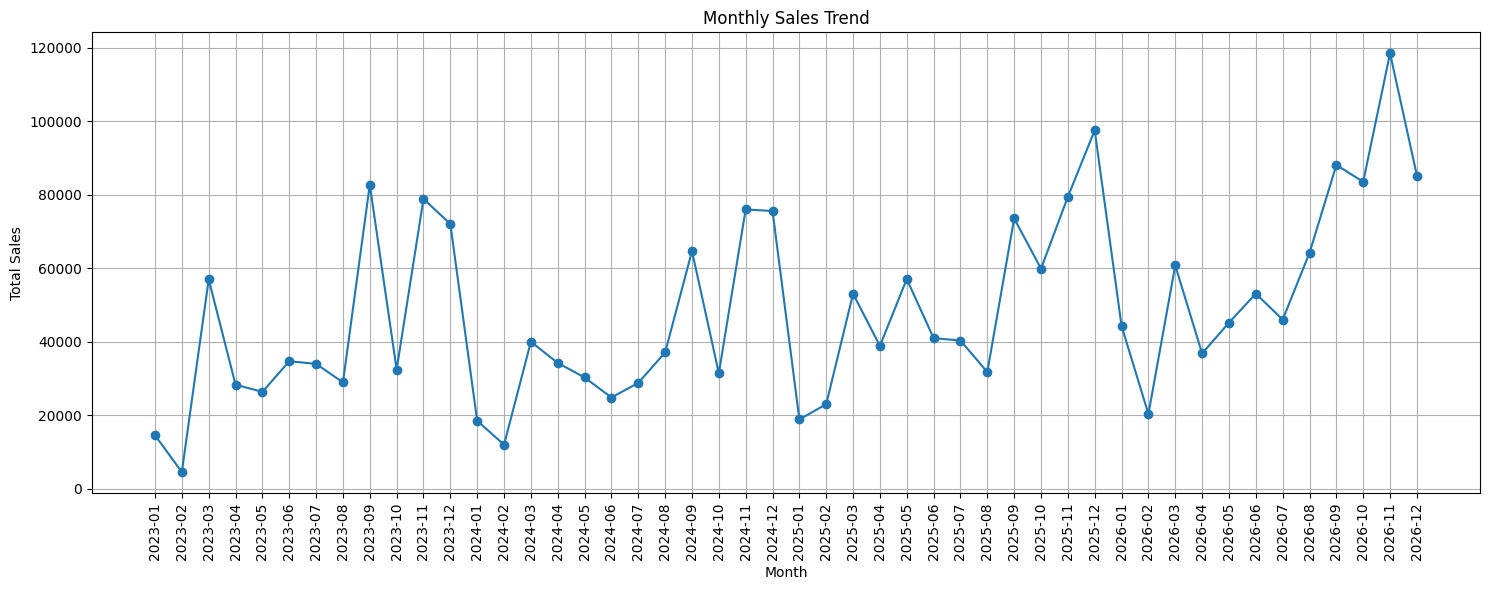

In [36]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 6))

plt.plot(
    monthly_analysis.index.astype(str),
    monthly_analysis["Total_Sales"],
    marker="o"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")

plt.xticks(rotation=90)
plt.grid(True)
plt.tight_layout()

plt.show()

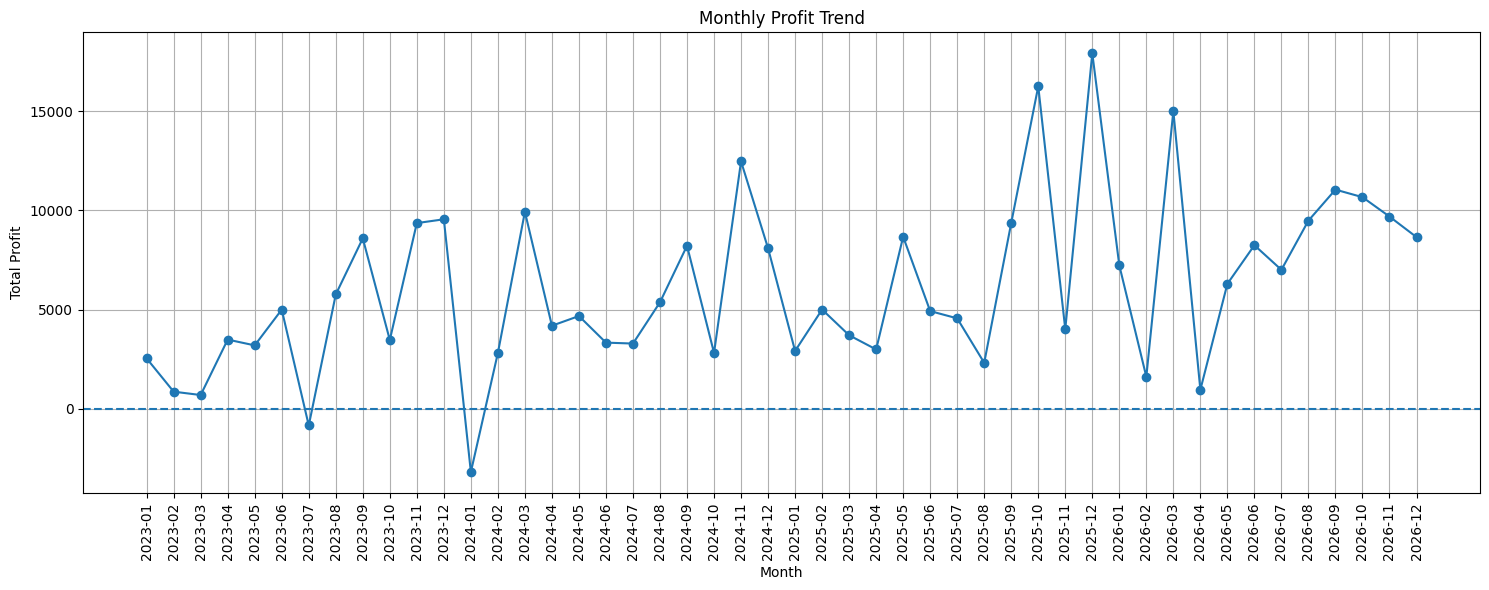

In [37]:
plt.figure(figsize=(15, 6))

plt.plot(
    monthly_analysis.index.astype(str),
    monthly_analysis["Total_Profit"],
    marker="o"
)

plt.axhline(y=0, linestyle="--")

plt.title("Monthly Profit Trend")
plt.xlabel("Month")
plt.ylabel("Total Profit")

plt.xticks(rotation=90)
plt.grid(True)
plt.tight_layout()

plt.show()

In [38]:
loss_months = monthly_analysis[monthly_analysis["Total_Profit"] < 0]

print("Number of loss-making months:", len(loss_months))
print("\nLoss-making months:")
print(loss_months[["Total_Sales", "Total_Profit"]])

Number of loss-making months: 2

Loss-making months:
             Total_Sales  Total_Profit
Order Month                           
2023-07       33946.3930     -841.4826
2024-01       18461.9156    -3189.8030


In [39]:
monthly_analysis[monthly_analysis["Total_Profit"] < 0]

,Total_Sales,Total_Profit,Total_Orders,Total_Quantity
Order Month,,,,
2023-07,33946.3930,-841.4826,65,550
2024-01,18461.9156,-3189.8030,31,260


### Monthly Profitability Analysis

Key Findings:
- 2 months recorded negative profit.
- July 2023 recorded a loss of 841.48.
- January 2024 recorded the largest monthly loss of 3,189.80.
- Both months generated sales but ended with negative profit.

Business Insight:
Revenue generation alone does not guarantee profitability. Loss-making months should be investigated further by examining product categories, discount levels, and individual transactions.

Recommendation:
Investigate the transactions contributing to negative monthly profit to identify potential pricing, discounting, or product profitability issues.

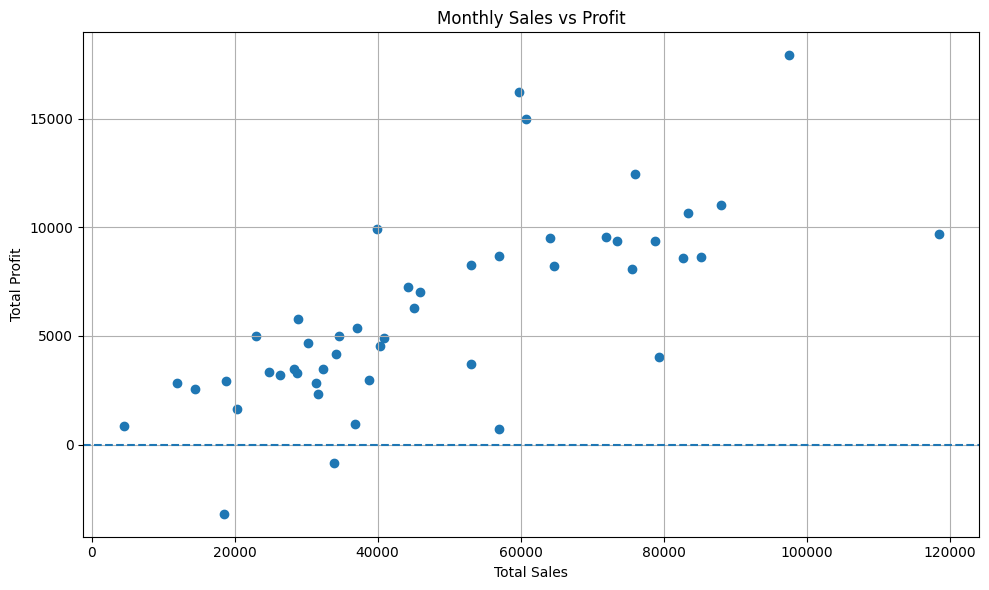

In [40]:
plt.figure(figsize=(10, 6))

plt.scatter(
    monthly_analysis["Total_Sales"],
    monthly_analysis["Total_Profit"]
)

plt.axhline(y=0, linestyle="--")

plt.title("Monthly Sales vs Profit")
plt.xlabel("Total Sales")
plt.ylabel("Total Profit")

plt.grid(True)
plt.tight_layout()

plt.show()

In [41]:
sales_profit_correlation = monthly_analysis["Total_Sales"].corr(
    monthly_analysis["Total_Profit"]
)

print("Sales-Profit Correlation:", sales_profit_correlation)

Sales-Profit Correlation: 0.72165038455959


### Sales vs. Profit Relationship

Analysis:
- Monthly sales and profit show a strong positive correlation.
- Correlation coefficient: 0.7217.
- Higher sales are generally associated with higher profits.
- However, some months generate relatively low profit despite substantial sales.

Business Insight:
Sales growth generally supports profit growth, but revenue alone is not a reliable measure of business performance.

Recommendation:
Monitor profit margins alongside sales and investigate months where sales are high but profit is comparatively low.

Limitation:
Correlation measures association, not causation. It does not establish that increasing sales alone will cause profits to increase.

## 11. Product Analysis

In [42]:
product_analysis = df.groupby("Product Name").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum"),
    Total_Orders=("Order ID", "nunique")
)

product_analysis.sort_values(by="Total_Profit", ascending=False)

,Total_Sales,Total_Profit,Total_Quantity,Total_Orders
Product Name,,,,
Canon imageCLASS 2200 Advanced Copier,61599.824,25199.9280,20,5
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind,27453.384,7753.0390,31,10
Hewlett Packard LaserJet 3310 Copier,18839.686,6983.8836,38,8
Canon PC1060 Personal Laser Copier,11619.834,4570.9347,19,4
"HP Designjet T520 Inkjet Large Format Printer - 24"" Color",18374.895,4094.9766,12,3
...,...,...,...,...
Bush Advantage Collection Racetrack Conference Table,9544.725,-1934.3976,33,7
Chromcraft Bull-Nose Wood Oval Conference Tables & Bases,9917.640,-2876.1156,27,5
Cubify CubeX 3D Printer Triple Head Print,7999.980,-3839.9904,4,1


In [43]:
top_10_products = product_analysis.sort_values(
    by="Total_Profit",
    ascending=False
).head(10)

top_10_products

,Total_Sales,Total_Profit,Total_Quantity,Total_Orders
Product Name,,,,
Canon imageCLASS 2200 Advanced Copier,61599.824,25199.9280,20,5
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind,27453.384,7753.0390,31,10
Hewlett Packard LaserJet 3310 Copier,18839.686,6983.8836,38,8
Canon PC1060 Personal Laser Copier,11619.834,4570.9347,19,4
"HP Designjet T520 Inkjet Large Format Printer - 24"" Color",18374.895,4094.9766,12,3
Ativa V4110MDD Micro-Cut Shredder,7699.890,3772.9461,11,2
"3D Systems Cube Printer, 2nd Generation, Magenta",14299.890,3717.9714,11,2
Plantronics Savi W720 Multi-Device Wireless Headset System,9367.290,3696.2820,24,7
Ibico EPK-21 Electric Binding System,15875.916,3345.2823,13,3


In [44]:
bottom_10_products = product_analysis.sort_values(
    by="Total_Profit",
    ascending=True
).head(10)

bottom_10_products

,Total_Sales,Total_Profit,Total_Quantity,Total_Orders
Product Name,,,,
Cubify CubeX 3D Printer Double Head Print,11099.963,-8879.9704,9,3
Lexmark MX611dhe Monochrome Laser Printer,16829.901,-4589.9730,18,4
Cubify CubeX 3D Printer Triple Head Print,7999.980,-3839.9904,4,1
Chromcraft Bull-Nose Wood Oval Conference Tables & Bases,9917.640,-2876.1156,27,5
Bush Advantage Collection Racetrack Conference Table,9544.725,-1934.3976,33,7
GBC DocuBind P400 Electric Binding System,17965.068,-1878.1662,27,6
Cisco TelePresence System EX90 Videoconferencing Unit,22638.480,-1811.0784,6,1
Martin Yale Chadless Opener Electric Letter Opener,16656.200,-1299.1836,22,6
Balt Solid Wood Round Tables,6518.754,-1201.0581,19,4


### Product-Level Profitability Analysis

Key Findings:
- The Canon imageCLASS 2200 Advanced Copier is the most profitable product, generating 25,199.93 in profit.
- The Cubify CubeX 3D Printer Double Head Print generated the largest product-level loss of 8,879.97.
- Both Cubify 3D Printer models appear among the 3 most loss-making products.
- Several conference and meeting table products also appear among the bottom 10 loss-making products.
- Product profitability varies significantly, and high sales do not necessarily translate into positive profit.

Business Insight:
Profitability is concentrated among certain products, while some products consistently contribute negative profit. Product-level performance should be monitored rather than relying only on category-level sales.

Recommendation:
Review pricing, discounts, and product costs for the most loss-making products. Prioritize investigation of the Cubify 3D printer models and loss-making table products.

Limitation:
The analysis identifies loss-making products but does not establish the exact reasons for their losses.

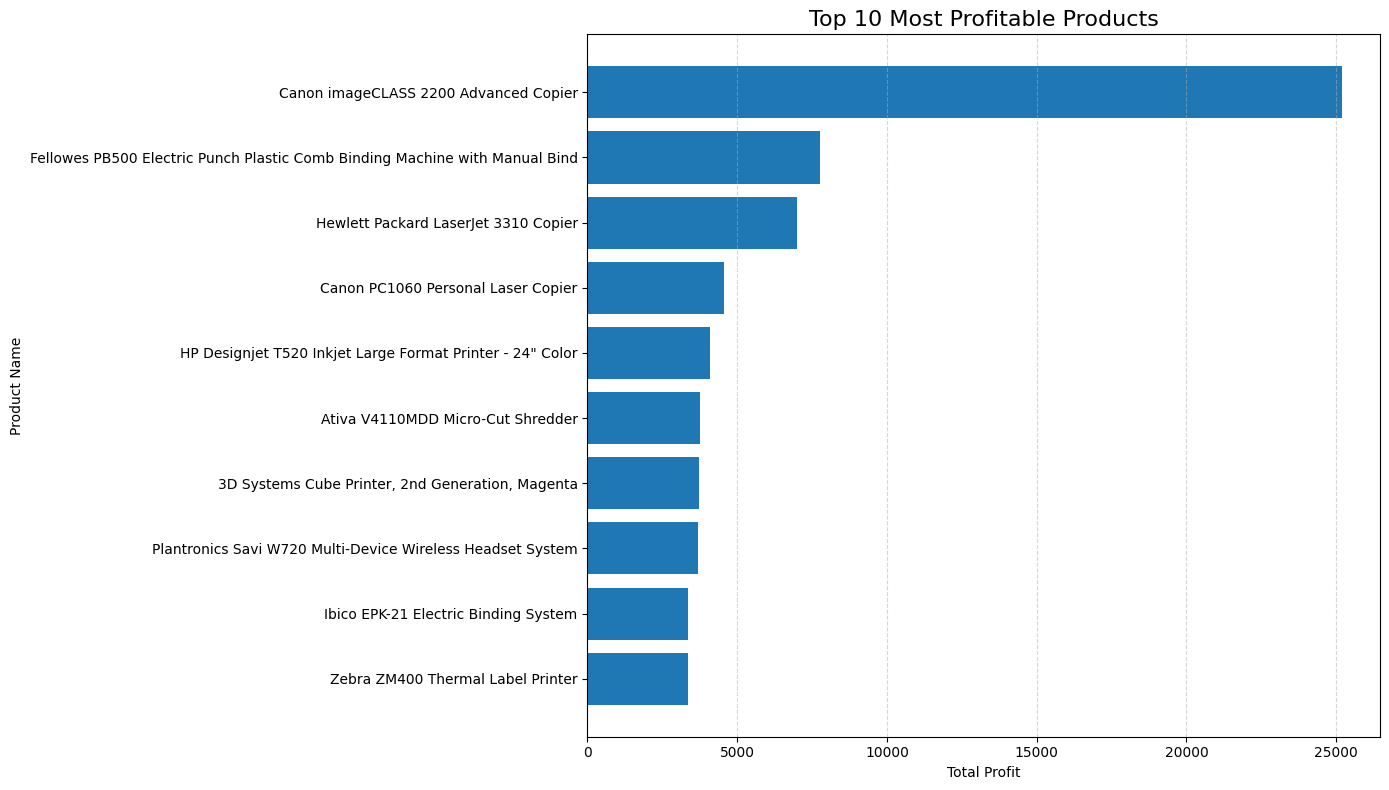

In [45]:
plt.figure(figsize=(14, 8))

plt.barh(
    top_10_products.index[::-1],
    top_10_products["Total_Profit"][::-1]
)

plt.title("Top 10 Most Profitable Products", fontsize=16)
plt.xlabel("Total Profit")
plt.ylabel("Product Name")

plt.grid(axis="x", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

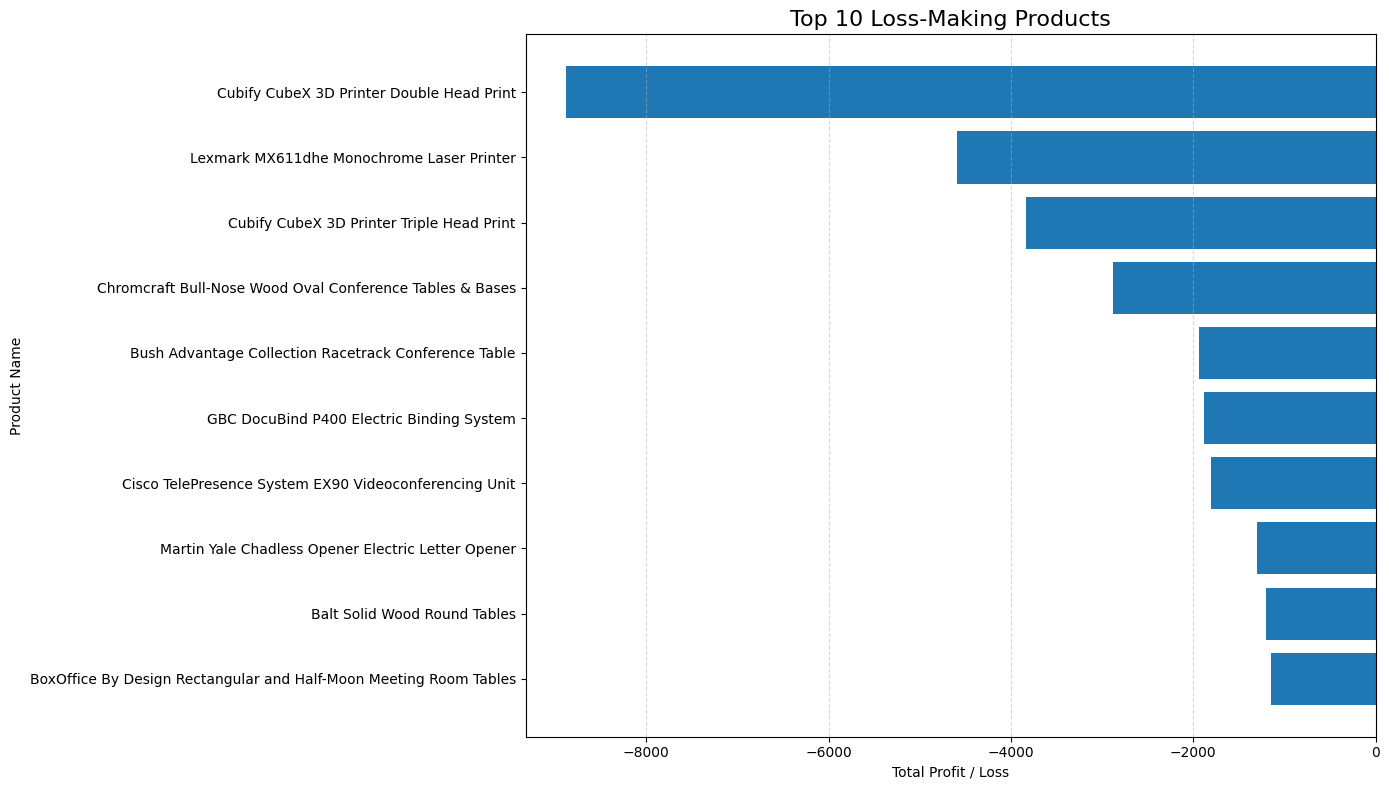

In [46]:
plt.figure(figsize=(14, 8))

plt.barh(
    bottom_10_products.index[::-1],
    bottom_10_products["Total_Profit"][::-1]
)

plt.title("Top 10 Loss-Making Products", fontsize=16)
plt.xlabel("Total Profit / Loss")
plt.ylabel("Product Name")

plt.grid(axis="x", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

### Product Profitability Visualization

Key Findings:
- The Canon imageCLASS 2200 Advanced Copier is the most profitable product, with a total profit of 25,199.93.
- The Cubify CubeX 3D Printer Double Head Print is the largest loss-making product, with a loss of 8,879.97.
- Losses are concentrated among certain products rather than distributed equally.
- The Cubify 3D printer models and several table products appear among the worst-performing products.

Business Insight:
A small number of products contribute disproportionately to product-level losses. Identifying these products enables targeted profitability investigation.

Recommendation:
Prioritize the largest loss-making products for reviews of pricing, discount strategy, product costs, and sales performance.

Limitation:
Product-level profit analysis identifies where losses occur but does not determine the underlying causes.

In [47]:
product_analysis["Profit_Margin"] = (
    product_analysis["Total_Profit"] /
    product_analysis["Total_Sales"]
) * 100

product_analysis.sort_values(
    by="Profit_Margin",
    ascending=False
)

,Total_Sales,Total_Profit,Total_Quantity,Total_Orders,Profit_Margin
Product Name,,,,,
Canon imageCLASS MF7460 Monochrome Digital Laser Multifunction Copier,3991.980,1995.9900,2,1,50.000000
"Adams Telephone Message Book w/Frequently-Called Numbers Space, 400 Messages per Book",223.440,111.7200,28,7,50.000000
Tops Green Bar Computer Printout Paper,342.580,171.2900,7,3,50.000000
Xerox 1890,244.700,122.3500,5,2,50.000000
Southworth Structures Collection,72.800,36.4000,10,2,50.000000
...,...,...,...,...,...
Zebra GK420t Direct Thermal/Thermal Transfer Printer,703.710,-938.2800,6,1,-133.333333
Okidata B401 Printer,179.991,-251.9874,3,1,-140.000000
Euro Pro Shark Stick Mini Vacuum,170.744,-325.6332,11,3,-190.714286


In [48]:
filtered_products = product_analysis[
    product_analysis["Total_Sales"] >= 1000
]

top_10_margin_products = filtered_products.sort_values(
    by="Profit_Margin",
    ascending=False
).head(10)

top_10_margin_products

,Total_Sales,Total_Profit,Total_Quantity,Total_Orders,Profit_Margin
Product Name,,,,,
Canon imageCLASS MF7460 Monochrome Digital Laser Multifunction Copier,3991.980,1995.9900,2,1,50.000000
Hewlett-Packard Desktjet 6988DT Refurbished Printer,3404.500,1668.2050,5,1,49.000000
Ativa V4110MDD Micro-Cut Shredder,7699.890,3772.9461,11,2,49.000000
Hewlett-Packard Deskjet 3050a All-in-One Color Inkjet Printer,3040.000,1459.2000,8,1,48.000000
Zebra ZM400 Thermal Label Printer,6965.700,3343.5360,6,2,48.000000
Xerox 1934,1097.208,526.2120,20,5,47.959184
Cisco SPA525G2 5-Line IP Phone,1379.920,648.5624,8,1,47.000000
Xerox 1917,1222.750,574.6925,25,5,47.000000
"GE 48"" Fluorescent Tube, Cool White Energy Saver, 34 Watts, 30/Box",2699.056,1260.2210,29,8,46.691176


### Product Profit Margin Analysis

Key Findings:
- Several products achieved profit margins above 46% after applying a minimum sales threshold of 1,000.
- The Canon imageCLASS MF7460 Copier achieved the highest margin in the filtered results at 50%.
- The Ativa V4110MDD Micro-Cut Shredder generated 3,772.95 profit with a 49% margin.
- High profit margins and high total profits are different metrics; both should be evaluated.

Business Insight:
Some products generate strong profit relative to their sales value. These products may represent attractive opportunities for the business, but total profit and sales volume should also be considered.

Recommendation:
Evaluate products using sales, total profit, profit margin, quantity sold, and order count rather than relying on a single metric.

Limitation:
The minimum sales threshold of 1,000 was selected for exploratory analysis and is not a predefined business requirement.

## 12. Customer Analysis

In [49]:
customer_analysis = df.groupby("Customer ID").agg(
    Customer_Name=("Customer Name", "first"),
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum"),
    Total_Orders=("Order ID", "nunique")
)

customer_analysis.sort_values(
    by="Total_Sales",
    ascending=False
)

,Customer_Name,Total_Sales,Total_Profit,Total_Quantity,Total_Orders
Customer ID,,,,,
SM-20320,Sean Miller,25043.050,-1980.7393,50,5
TC-20980,Tamara Chand,19052.218,8981.3239,42,5
RB-19360,Raymond Buch,15117.339,6976.0959,71,6
TA-21385,Tom Ashbrook,14595.620,4703.7883,36,4
AB-10105,Adrian Barton,14473.571,5444.8055,73,10
...,...,...,...,...,...
MG-18205,Mitch Gastineau,16.739,-1.2453,8,1
CJ-11875,Carl Jackson,16.520,1.6520,5,1
HO-15230,Harry Olson,6.048,-1.2096,6,2


In [50]:
top_10_customers = customer_analysis.sort_values(
    by="Total_Sales",
    ascending=False
).head(10)

top_10_customers


,Customer_Name,Total_Sales,Total_Profit,Total_Quantity,Total_Orders
Customer ID,,,,,
SM-20320,Sean Miller,25043.050,-1980.7393,50,5
TC-20980,Tamara Chand,19052.218,8981.3239,42,5
RB-19360,Raymond Buch,15117.339,6976.0959,71,6
TA-21385,Tom Ashbrook,14595.620,4703.7883,36,4
AB-10105,Adrian Barton,14473.571,5444.8055,73,10
KL-16645,Ken Lonsdale,14175.229,806.8550,113,12
SC-20095,Sanjit Chand,14142.334,5757.4119,87,9
HL-15040,Hunter Lopez,12873.298,5622.4292,50,6
SE-20110,Sanjit Engle,12209.438,2650.6769,78,11


In [51]:
top_10_profitable_customers = customer_analysis.sort_values(
    by="Total_Profit",
    ascending=False
).head(10)

top_10_profitable_customers

,Customer_Name,Total_Sales,Total_Profit,Total_Quantity,Total_Orders
Customer ID,,,,,
TC-20980,Tamara Chand,19052.218,8981.3239,42,5
RB-19360,Raymond Buch,15117.339,6976.0959,71,6
SC-20095,Sanjit Chand,14142.334,5757.4119,87,9
HL-15040,Hunter Lopez,12873.298,5622.4292,50,6
AB-10105,Adrian Barton,14473.571,5444.8055,73,10
TA-21385,Tom Ashbrook,14595.620,4703.7883,36,4
CM-12385,Christopher Martinez,8954.020,3899.8904,34,4
KD-16495,Keith Dawkins,8181.256,3038.6254,84,12
AR-10540,Andy Reiter,6608.448,2884.6208,33,6


### Customer Profitability Analysis

Key Findings:
- Sean Miller generated the highest customer sales at 25,043.05 but recorded a loss of 1,980.74.
- Tamara Chand is the most profitable customer, generating 8,981.32 profit.
- Raymond Buch is the second-most profitable customer, generating 6,976.10 profit.
- High revenue does not always translate into high profitability.
- Customer rankings differ when based on sales versus profit.

Business Insight:
Customer value should be measured using multiple metrics, including sales, profit, order frequency, quantity purchased, and profitability rather than revenue alone.

Recommendation:
Prioritize profitable customers for retention strategies while investigating high-sales customers with low or negative profit to identify opportunities for improving profitability.

Limitation:
Customer-level profit totals identify profitable and loss-making customers but do not independently explain the causes of their profitability.

In [52]:
customer_analysis["Profit_Margin"] = (
    customer_analysis["Total_Profit"] /
    customer_analysis["Total_Sales"]
) * 100

customer_analysis.sort_values(
    by="Profit_Margin",
    ascending=False
)

,Customer_Name,Total_Sales,Total_Profit,Total_Quantity,Total_Orders,Profit_Margin
Customer ID,,,,,,
JC-15385,Jenna Caffey,1058.108,502.9244,14,1,47.530536
TC-20980,Tamara Chand,19052.218,8981.3239,42,5,47.140569
RB-19360,Raymond Buch,15117.339,6976.0959,71,6,46.146322
SR-20740,Steven Roelle,4345.886,1990.4244,50,8,45.800198
BO-11425,Bobby Odegard,130.830,59.4522,7,2,45.442330
...,...,...,...,...,...,...
LF-17185,Luke Foster,3930.509,-3583.9770,69,7,-91.183534
NC-18415,Nathan Cano,2218.990,-2204.8072,38,6,-99.360844
SR-20425,Sharelle Roach,3233.481,-3333.9144,34,5,-103.106046


In [53]:
filtered_customers = customer_analysis[
    customer_analysis["Total_Sales"] >= 1000
]

top_10_margin_customers = filtered_customers.sort_values(
    by="Profit_Margin",
    ascending=False
).head(10)

top_10_margin_customers

,Customer_Name,Total_Sales,Total_Profit,Total_Quantity,Total_Orders,Profit_Margin
Customer ID,,,,,,
JC-15385,Jenna Caffey,1058.108,502.9244,14,1,47.530536
TC-20980,Tamara Chand,19052.218,8981.3239,42,5,47.140569
RB-19360,Raymond Buch,15117.339,6976.0959,71,6,46.146322
SR-20740,Steven Roelle,4345.886,1990.4244,50,8,45.800198
HL-15040,Hunter Lopez,12873.298,5622.4292,50,6,43.675127
AR-10540,Andy Reiter,6608.448,2884.6208,33,6,43.650503
CM-12385,Christopher Martinez,8954.020,3899.8904,34,4,43.554631
NM-18445,Nathan Mautz,6459.344,2751.6849,44,7,42.600067
NP-18685,Nora Pelletier,1228.698,514.5017,23,6,41.873731


### Customer Profit Margin Analysis

Profit margin was calculated for each customer to evaluate profitability relative to their total sales. Customers were then ranked by profit margin.

To avoid rankings being dominated by customers with very small sales amounts, a minimum sales threshold of 1,000 was applied.

#### Key Findings
- Jenna Caffey had the highest profit margin at approximately 47.53%.
- Tamara Chand had a 47.14% profit margin while generating 19,052.22 in sales and 8,981.32 in profit.
- Raymond Buch generated a 46.15% profit margin and 6,976.10 in profit.
- Several customers demonstrated strong profit margins alongside substantial sales.
- High profit margin and high total profit are different measures of customer profitability.

#### Business Recommendations
- Identify and retain customers who generate both strong sales and high profit margins.
- Evaluate customer profitability using sales, profit, margin, order frequency, and quantity.
- Investigate customers generating negative profits to identify potential pricing, discount, or product-mix issues.
- Avoid evaluating customers using profit margin alone.

**Note:** The minimum sales threshold of 1,000 was an exploratory analytical choice.

In [54]:
top_10_frequent_customers = customer_analysis.sort_values(
    by="Total_Orders",
    ascending=False
).head(10)

top_10_frequent_customers

,Customer_Name,Total_Sales,Total_Profit,Total_Quantity,Total_Orders,Profit_Margin
Customer ID,,,,,,
EP-13915,Emily Phan,5478.0608,144.9578,124,17,2.646152
EH-14125,Eugene Hildebrand,3143.4830,117.8102,84,14,3.747760
SM-20950,Suzanne McNair,5695.7900,610.1142,103,14,10.711669
BP-11095,Bart Pistole,3350.8740,702.9642,85,14,20.978533
ZC-21910,Zuschuss Carroll,8025.7070,-1032.1490,105,13,-12.860537
XP-21865,Xylona Preis,2503.1560,675.9584,121,13,27.004246
PG-18820,Patrick Gardner,3086.9070,137.4613,83,13,4.453043
EA-14035,Erin Ashbrook,2846.7050,-52.7406,87,13,-1.852689
NS-18640,Noel Staavos,2964.8230,-234.7714,113,13,-7.918564


In [55]:
customer_analysis["Average_Order_Value"] = (
    customer_analysis["Total_Sales"] /
    customer_analysis["Total_Orders"]
)

customer_analysis.sort_values(
    by="Average_Order_Value",
    ascending=False
)

,Customer_Name,Total_Sales,Total_Profit,Total_Quantity,Total_Orders,Profit_Margin,Average_Order_Value
Customer ID,,,,,,,
SM-20320,Sean Miller,25043.050,-1980.7393,50,5,-7.909337,5008.610000
TC-20980,Tamara Chand,19052.218,8981.3239,42,5,47.140569,3810.443600
TA-21385,Tom Ashbrook,14595.620,4703.7883,36,4,32.227396,3648.905000
GT-14635,Grant Thornton,9351.212,-4108.6589,26,3,-43.937181,3117.070667
BM-11140,Becky Martin,11789.630,-1659.9581,64,4,-14.079815,2947.407500
...,...,...,...,...,...,...,...
RS-19870,Roy Skaria,22.328,9.5838,10,2,42.922788,11.164000
JS-13215,Jennifer Sheldon,19.980,8.9910,2,2,45.000000,9.990000
LD-16855,Lela Donovan,5.304,0.4641,3,1,8.750000,5.304000


### Customer Purchasing Behavior and Average Order Value

Customer purchasing behavior was analyzed using order frequency, total quantity purchased, total sales, profit, and Average Order Value (AOV).

AOV was calculated by dividing total customer sales by the number of unique orders.

#### Key Findings
- Emily Phan had the highest order frequency with 17 orders.
- Frequent purchasing does not necessarily translate into high profitability.
- Sean Miller had the highest Average Order Value among the displayed customers, at 5,008.61, but generated a total loss of 1,980.74.
- Tamara Chand demonstrated strong customer profitability, combining high sales, high AOV, and a strong profit margin.
- Customers with high order frequency and customers with high order value represent different purchasing behavior patterns.

#### Business Recommendations
- Identify frequent customers and evaluate their profitability.
- Investigate high-value orders that generate negative profit.
- Develop strategies to increase average order value without sacrificing profit margins.
- Evaluate customer performance using sales, profit, margin, order frequency, and AOV together.

## 13. State-Level Analysis

In [56]:
state_analysis = df.groupby("State/Province").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum"),
    Total_Orders=("Order ID", "nunique"),
    Total_Customers=("Customer ID", "nunique")
)

state_analysis.sort_values(
    by="Total_Sales",
    ascending=False
)

,Total_Sales,Total_Profit,Total_Quantity,Total_Orders,Total_Customers
State/Province,,,,,
California,457687.6315,76381.3871,7667,1021,577
New York,310876.2710,74038.5486,4224,562,415
Texas,170188.0458,-25729.3563,3724,487,370
Washington,138641.2700,33402.6517,1883,256,224
Pennsylvania,116511.9140,-15559.9603,2153,288,257
Florida,89473.7080,-3399.3017,1379,200,181
Illinois,80166.1010,-12607.8870,1845,276,237
Ohio,78258.1360,-16971.3766,1759,236,202
Michigan,76269.6140,24463.1876,946,117,106


In [57]:
state_analysis["Profit_Margin"] = (
    state_analysis["Total_Profit"] /
    state_analysis["Total_Sales"]
) * 100

state_analysis.sort_values(
    by="Profit_Margin",
    ascending=False
)

,Total_Sales,Total_Profit,Total_Quantity,Total_Orders,Total_Customers,Profit_Margin
State/Province,,,,,,
District of Columbia,2865.0200,1059.5893,40,4,4,36.983662
Delaware,27451.0690,9977.3748,367,44,43,36.346034
Minnesota,29863.1500,10823.1874,331,44,42,36.242618
Newfoundland and Labrador,515.2000,186.6760,45,5,1,36.233696
Maine,1270.5300,454.4862,35,3,3,35.771387
Arkansas,11678.1300,4008.6871,240,27,27,34.326447
Indiana,53555.3600,18382.9363,578,73,70,34.325110
Georgia,49095.8400,16250.0433,705,91,83,33.098615
Montana,5589.3520,1833.3285,56,8,8,32.800377


### State-Level Sales and Profitability Analysis

Sales, profit, quantity, orders, and customer performance were aggregated by state/province to evaluate geographic business performance.

Profit margin was calculated to compare profitability relative to sales.

#### Key Findings
- California generated the highest sales (457,687.63) and total profit (76,381.39).
- New York generated 310,876.27 in sales and 74,038.55 in profit, with a profit margin of 23.82%.
- Washington generated 138,641.27 in sales with a strong profit margin of 24.09%.
- Texas generated 170,188.05 in sales but recorded the largest geographic loss of 25,729.36.
- Ohio and Pennsylvania also recorded substantial losses despite significant sales.
- Vermont had the highest profit margin at approximately 25.14%, but its sales volume was relatively small.

#### Business Recommendations
- Investigate Texas, Ohio, and Pennsylvania to understand the causes of negative profitability.
- Analyze discounts, product mix, and sub-category profitability in loss-making states.
- Maintain focus on high-sales and high-profit locations such as California and New York.
- Evaluate geographic performance using both absolute profit and profit margin rather than relying on sales alone.

**Note:** Profit margin rankings should be interpreted alongside sales volume and absolute profit/loss. Low-volume locations can have extreme margins without representing a significant financial impact.

## 14. Shipping Mode Analysis

In [58]:
shipping_analysis = df.groupby("Ship Mode").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum"),
    Total_Orders=("Order ID", "nunique"),
    Total_Customers=("Customer ID", "nunique")
)

shipping_analysis.sort_values(
    by="Total_Orders",
    ascending=False
)

,Total_Sales,Total_Profit,Total_Quantity,Total_Orders,Total_Customers
Ship Mode,,,,,
Standard Class,1.378841e+06,168161.2095,23409,3068,783
Second Class,4.666711e+05,58962.1329,7546,982,553
First Class,3.517507e+05,49012.7242,5724,795,494
Same Day,1.292720e+05,16160.7480,1975,266,227


In [59]:
shipping_analysis["Profit_Margin"] = (
    shipping_analysis["Total_Profit"] /
    shipping_analysis["Total_Sales"]
) * 100

shipping_analysis["Average_Order_Value"] = (
    shipping_analysis["Total_Sales"] /
    shipping_analysis["Total_Orders"]
)

shipping_analysis.sort_values(
    by="Profit_Margin",
    ascending=False
)

,Total_Sales,Total_Profit,Total_Quantity,Total_Orders,Total_Customers,Profit_Margin,Average_Order_Value
Ship Mode,,,,,,,
First Class,3.517507e+05,49012.7242,5724,795,494,13.933936,442.453757
Second Class,4.666711e+05,58962.1329,7546,982,553,12.634622,475.225164
Same Day,1.292720e+05,16160.7480,1975,266,227,12.501357,485.984793
Standard Class,1.378841e+06,168161.2095,23409,3068,783,12.195842,449.426516


### Shipping Mode Analysis

**Key Findings:**

- Standard Class generated the highest sales (1,378,841.21) and total profit (168,161.21), supported by the highest order volume of 3,068 orders.
- First Class achieved the highest profit margin at 13.93%, indicating better profitability relative to sales among the shipping modes.
- Same Day shipping recorded the highest average order value (485.98), followed by Second Class (475.23).
- Standard Class had the lowest profit margin at 12.20%, despite contributing the largest share of sales and total profit.

**Business Recommendations:**

- Continue monitoring Standard Class because it contributes the largest volume of business.
- Evaluate First Class performance to understand the factors associated with its higher profit margin.
- Analyze Same Day orders to understand their higher average order value.
- Compare profitability, order volume, and average order value together when evaluating shipping performance.

**Limitation:** The dataset does not contain actual shipping costs, so the analysis cannot directly measure the cost-effectiveness of each shipping method or determine whether faster shipping causes changes in profitability.

## 15. Yearly and Year-over-Year Analysis

In [60]:
df["Order Year"] = df["Order Date"].dt.year

df[["Order Date", "Order Year"]].head()

,Order Date,Order Year
0,2023-01-03,2023
1,2023-01-04,2023
2,2023-01-04,2023
3,2023-01-04,2023
4,2023-01-05,2023


In [61]:
yearly_analysis = df.groupby("Order Year").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Orders=("Order ID", "nunique"),
    Total_Quantity=("Quantity", "sum")
)

yearly_analysis


,Total_Sales,Total_Profit,Total_Orders,Total_Quantity
Order Year,,,,
2023,494040.2121,51684.2957,995,7813
2024,472993.0310,62020.9695,1053,8086
2025,613933.5800,82665.2018,1340,10018
2026,745567.5312,95926.3476,1723,12737


In [62]:
yearly_growth = yearly_analysis.pct_change() * 100

yearly_growth

,Total_Sales,Total_Profit,Total_Orders,Total_Quantity
Order Year,,,,
2023,NaN,NaN,NaN,NaN
2024,-4.260216,19.999641,5.829146,3.494176
2025,29.797595,33.285891,27.255461,23.893149
2026,21.441074,16.041993,28.582090,27.141146


### Year-over-Year Performance Analysis

**Key Findings:**

- Sales declined by 4.26% in 2024 compared with 2023, while profit increased by 20.00%.
- 2025 recorded strong growth, with sales increasing by 29.80%, profit by 33.29%, and orders by 27.26%.
- In 2026, sales increased by 21.44% and profit increased by 16.04%, indicating that profit growth was slower than sales growth.
- Order growth in 2026 reached 28.58%, exceeding sales growth, which suggests that average revenue per order declined relative to the previous year.

**Business Recommendations:**

- Investigate why profit improved in 2024 despite the sales decline.
- Identify the factors contributing to strong growth in 2025 and evaluate whether they can be sustained.
- Investigate the slower profit growth in 2026 despite higher sales and order volume.
- Monitor average order value and profit margin alongside sales growth.

**Data Limitation:** The dataset includes dates through December 2026. The 2026 results should be treated cautiously because the dataset's time period may not represent actual calendar reporting and may contain synthetic or future-dated records.

In [63]:
yearly_analysis["Profit_Margin"] = (
    yearly_analysis["Total_Profit"] /
    yearly_analysis["Total_Sales"]
) * 100

yearly_analysis

,Total_Sales,Total_Profit,Total_Orders,Total_Quantity,Profit_Margin
Order Year,,,,,
2023,494040.2121,51684.2957,995,7813,10.461556
2024,472993.0310,62020.9695,1053,8086,13.112449
2025,613933.5800,82665.2018,1340,10018,13.464844
2026,745567.5312,95926.3476,1723,12737,12.866218


### Yearly Profitability Analysis

**Key Findings:**

- 2023 recorded the lowest annual profit margin at 10.46%.
- Profit margin improved to 13.11% in 2024, despite a 4.26% decline in sales.
- 2025 achieved the highest profit margin at 13.46%, along with strong sales and profit growth.
- 2026 generated the highest total sales and profit, but its profit margin declined to 12.87% compared with 2025.

**Business Recommendations:**

- Investigate the factors responsible for improved profitability in 2024 and 2025.
- Review discounting, product mix, and loss-making categories to understand the margin decline in 2026.
- Focus on profitable growth rather than sales growth alone.
- Monitor yearly sales, profit, order volume, and profit margin together.

**Conclusion:** The business showed strong growth from 2024 onward. However, the decline in profit margin during 2026 suggests that profitability should be monitored carefully as sales and order volume continue to increase.

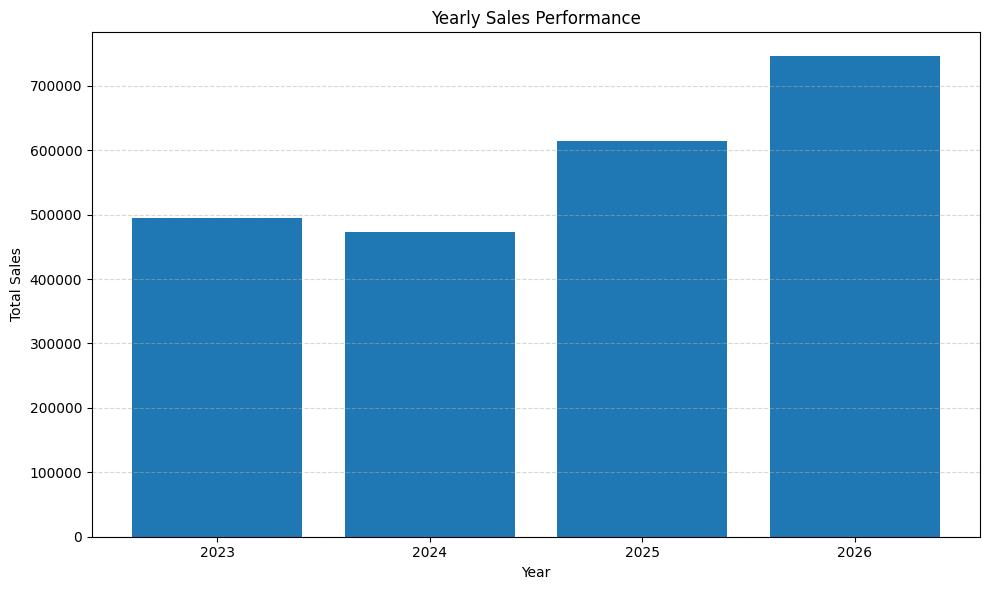

In [64]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.bar(
    yearly_analysis.index.astype(str),
    yearly_analysis["Total_Sales"]
)

plt.title("Yearly Sales Performance")
plt.xlabel("Year")
plt.ylabel("Total Sales")

plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

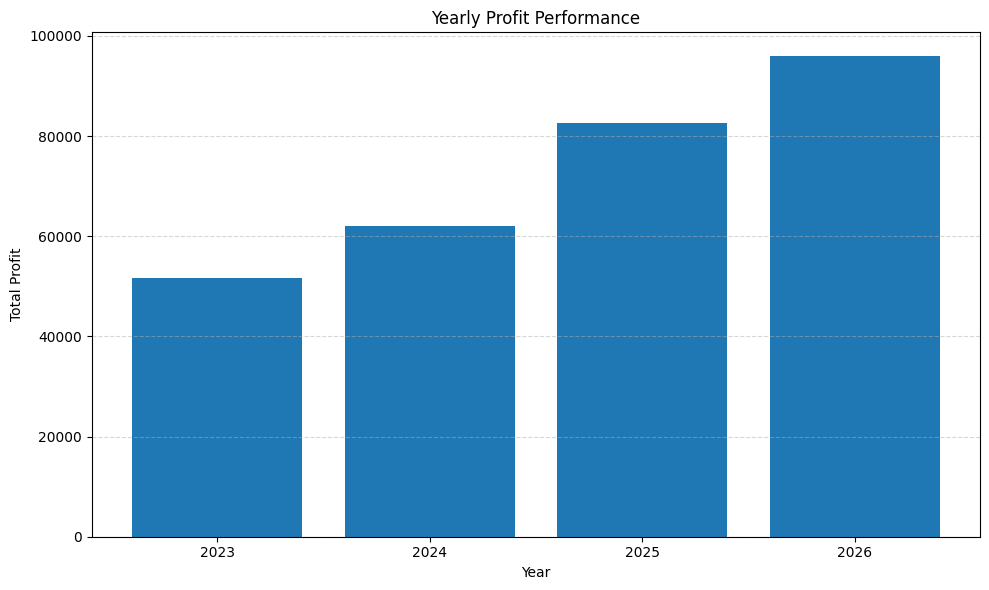

In [65]:
plt.figure(figsize=(10, 6))

plt.bar(
    yearly_analysis.index.astype(str),
    yearly_analysis["Total_Profit"]
)

plt.title("Yearly Profit Performance")
plt.xlabel("Year")
plt.ylabel("Total Profit")

plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

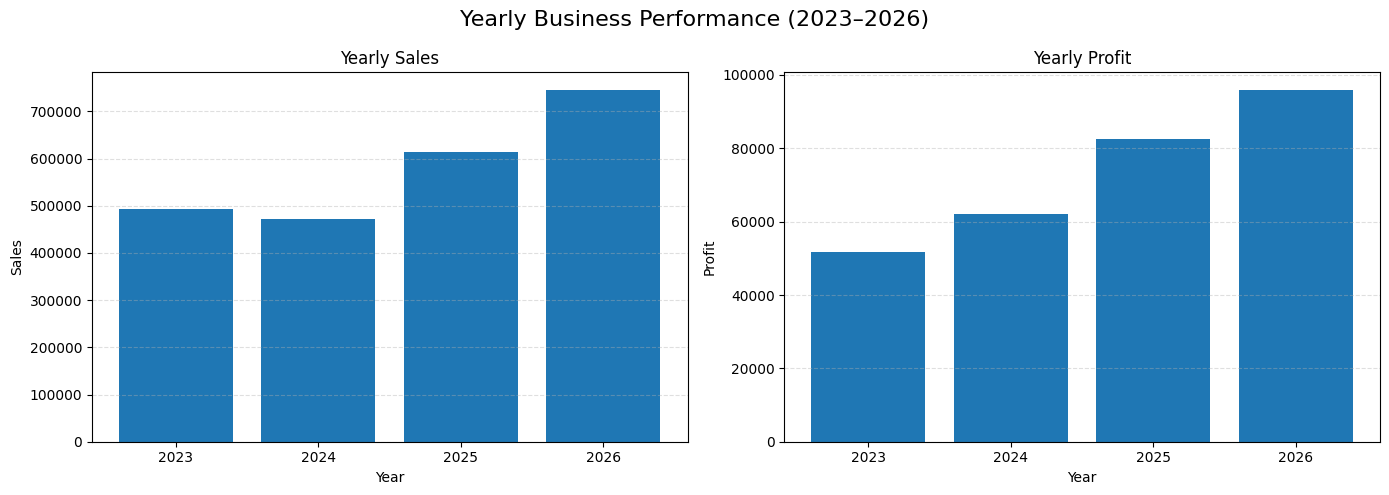

In [66]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Sales chart
axes[0].bar(
    yearly_analysis.index.astype(str),
    yearly_analysis["Total_Sales"]
)

axes[0].set_title("Yearly Sales")
axes[0].set_xlabel("Year")
axes[0].set_ylabel("Sales")
axes[0].grid(axis="y", linestyle="--", alpha=0.4)

# Profit chart
axes[1].bar(
    yearly_analysis.index.astype(str),
    yearly_analysis["Total_Profit"]
)

axes[1].set_title("Yearly Profit")
axes[1].set_xlabel("Year")
axes[1].set_ylabel("Profit")
axes[1].grid(axis="y", linestyle="--", alpha=0.4)

plt.suptitle("Yearly Business Performance (2023–2026)", fontsize=16)

plt.tight_layout()
plt.show()

### Yearly Sales and Profit Visualization

The yearly performance charts illustrate the business's sales and profit trends from 2023 to 2026.

**Observations:**
- Sales declined slightly in 2024 before recovering strongly in 2025 and 2026.
- Profit increased consistently across all four years.
- 2026 recorded the highest sales and profit.
- 2024 showed an improvement in profitability despite lower sales revenue.

**Business Insight:** The business demonstrated consistent profit growth throughout the analyzed period, even when sales declined in 2024. This indicates that revenue growth and profitability do not always move at the same rate and should be monitored independently.

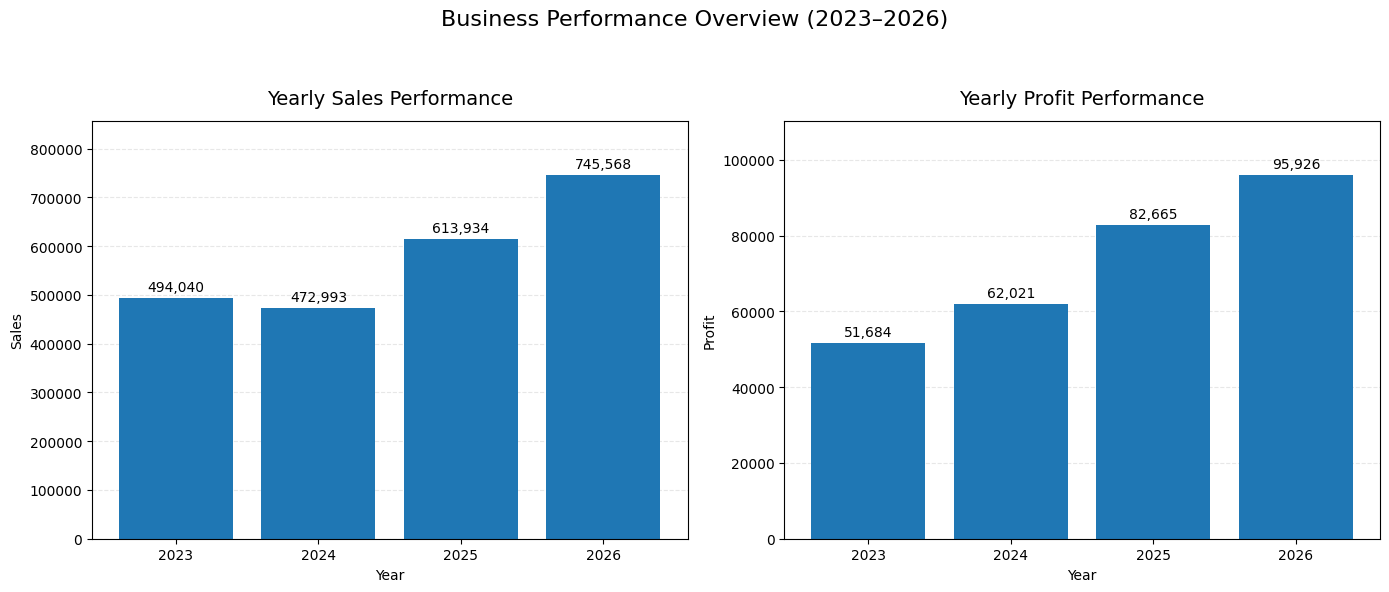

In [67]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Sales chart
sales_bars = axes[0].bar(
    yearly_analysis.index.astype(str),
    yearly_analysis["Total_Sales"]
)

axes[0].bar_label(
    sales_bars,
    labels=[f"{value:,.0f}" for value in yearly_analysis["Total_Sales"]],
    padding=3
)

axes[0].set_title("Yearly Sales Performance", fontsize=14, pad=12)
axes[0].set_xlabel("Year")
axes[0].set_ylabel("Sales")
axes[0].grid(axis="y", linestyle="--", alpha=0.3)
axes[0].set_axisbelow(True)
axes[0].set_ylim(0, yearly_analysis["Total_Sales"].max() * 1.15)

# Profit chart
profit_bars = axes[1].bar(
    yearly_analysis.index.astype(str),
    yearly_analysis["Total_Profit"]
)

axes[1].bar_label(
    profit_bars,
    labels=[f"{value:,.0f}" for value in yearly_analysis["Total_Profit"]],
    padding=3
)

axes[1].set_title("Yearly Profit Performance", fontsize=14, pad=12)
axes[1].set_xlabel("Year")
axes[1].set_ylabel("Profit")
axes[1].grid(axis="y", linestyle="--", alpha=0.3)
axes[1].set_axisbelow(True)
axes[1].set_ylim(0, yearly_analysis["Total_Profit"].max() * 1.15)

# Main title
fig.suptitle(
    "Business Performance Overview (2023–2026)",
    fontsize=16,
    y=0.98
)

# Leave room for the main title
plt.tight_layout(rect=[0, 0, 1, 0.93])

plt.show()

## 16. Aggregation Validation

In [68]:
print("Total Rows:", len(df))
print("Unique Orders:", df["Order ID"].nunique())
print("Unique Customers:", df["Customer ID"].nunique())
print("Total Sales:", df["Sales"].sum())
print("Total Profit:", df["Profit"].sum())
print("Overall Profit Margin:", (df["Profit"].sum() / df["Sales"].sum()) * 100)

Total Rows: 10194
Unique Orders: 5111
Unique Customers: 804
Total Sales: 2326534.3543
Total Profit: 292296.8145999999
Overall Profit Margin: 12.563614805849074


In [69]:
print("Category Sales Total:", category_analysis["Total_Sales"].sum())
print("Original Sales Total:", df["Sales"].sum())

print("\nCategory Profit Total:", category_analysis["Total_Profit"].sum())
print("Original Profit Total:", df["Profit"].sum())

Category Sales Total: 2326534.3543000002
Original Sales Total: 2326534.3543

Category Profit Total: 292296.8145999999
Original Profit Total: 292296.8145999999


In [70]:
print("Regional Sales Total:", region_analysis["Total_Sales"].sum())
print("Original Sales Total:", df["Sales"].sum())

print("\nRegional Profit Total:", region_analysis["Total_Profit"].sum())
print("Original Profit Total:", df["Profit"].sum())

Regional Sales Total: 2326534.3543000002
Original Sales Total: 2326534.3543

Regional Profit Total: 292296.8145999999
Original Profit Total: 292296.8145999999


In [71]:
print("Segment Sales Total:", segment_analysis["Total_Sales"].sum())
print("Original Sales Total:", df["Sales"].sum())

print("\nSegment Profit Total:", segment_analysis["Total_Profit"].sum())
print("Original Profit Total:", df["Profit"].sum())

Segment Sales Total: 2326534.3543000002
Original Sales Total: 2326534.3543

Segment Profit Total: 292296.8145999999
Original Profit Total: 292296.8145999999


In [72]:
print("Sub-Category Sales Total:", subcategory_analysis["Total_Sales"].sum())
print("Original Sales Total:", df["Sales"].sum())

print("\nSub-Category Profit Total:", subcategory_analysis["Total_Profit"].sum())
print("Original Profit Total:", df["Profit"].sum())

Sub-Category Sales Total: 2326534.3543
Original Sales Total: 2326534.3543

Sub-Category Profit Total: 292296.8146
Original Profit Total: 292296.8145999999


In [73]:
print("Monthly Sales Total:", monthly_analysis["Total_Sales"].sum())
print("Original Sales Total:", df["Sales"].sum())

print("\nMonthly Profit Total:", monthly_analysis["Total_Profit"].sum())
print("Original Profit Total:", df["Profit"].sum())

Monthly Sales Total: 2326534.3543
Original Sales Total: 2326534.3543

Monthly Profit Total: 292296.8145999999
Original Profit Total: 292296.8145999999


In [74]:
print("Yearly Sales Total:", yearly_analysis["Total_Sales"].sum())
print("Original Sales Total:", df["Sales"].sum())

print("\nYearly Profit Total:", yearly_analysis["Total_Profit"].sum())
print("Original Profit Total:", df["Profit"].sum())

Yearly Sales Total: 2326534.3543000002
Original Sales Total: 2326534.3543

Yearly Profit Total: 292296.8145999999
Original Profit Total: 292296.8145999999


In [75]:
print("Shipping Sales Total:", shipping_analysis["Total_Sales"].sum())
print("Original Sales Total:", df["Sales"].sum())

print("\nShipping Profit Total:", shipping_analysis["Total_Profit"].sum())
print("Original Profit Total:", df["Profit"].sum())

Shipping Sales Total: 2326534.3543
Original Sales Total: 2326534.3543

Shipping Profit Total: 292296.8145999999
Original Profit Total: 292296.8145999999


In [76]:
print("State Sales Total:", state_analysis["Total_Sales"].sum())
print("Original Sales Total:", df["Sales"].sum())

print("\nState Profit Total:", state_analysis["Total_Profit"].sum())
print("Original Profit Total:", df["Profit"].sum())

State Sales Total: 2326534.3543
Original Sales Total: 2326534.3543

State Profit Total: 292296.8146
Original Profit Total: 292296.8145999999


In [77]:
print("Discount Sales Total:", discount_analysis["Total_Sales"].sum())
print("Original Sales Total:", df["Sales"].sum())

print("\nDiscount Profit Total:", discount_analysis["Total_Profit"].sum())
print("Original Profit Total:", df["Profit"].sum())

Discount Sales Total: 2326534.3543
Original Sales Total: 2326534.3543

Discount Profit Total: 292296.8145999999
Original Profit Total: 292296.8145999999


In [78]:
print("Customer Sales Total:", customer_analysis["Total_Sales"].sum())
print("Original Sales Total:", df["Sales"].sum())

print("\nCustomer Profit Total:", customer_analysis["Total_Profit"].sum())
print("Original Profit Total:", df["Profit"].sum())

Customer Sales Total: 2326534.3543000002
Original Sales Total: 2326534.3543

Customer Profit Total: 292296.8145999999
Original Profit Total: 292296.8145999999


In [79]:
print("Product Sales Total:", product_analysis["Total_Sales"].sum())
print("Original Sales Total:", df["Sales"].sum())

print("\nProduct Profit Total:", product_analysis["Total_Profit"].sum())
print("Original Profit Total:", df["Profit"].sum())

Product Sales Total: 2326534.3543
Original Sales Total: 2326534.3543

Product Profit Total: 292296.8145999999
Original Profit Total: 292296.8145999999


In [80]:
print("Unique Products in Dataset:", df["Product Name"].nunique())
print("Products in Product Analysis:", len(product_analysis))

print("\nUnique Customers in Dataset:", df["Customer ID"].nunique())
print("Customers in Customer Analysis:", len(customer_analysis))

Unique Products in Dataset: 1849
Products in Product Analysis: 1849

Unique Customers in Dataset: 804
Customers in Customer Analysis: 804


## 17. Numerical Data Quality Checks

In [81]:
print("Negative Sales:", (df["Sales"] < 0).sum())
print("Zero Sales:", (df["Sales"] == 0).sum())

print("\nNegative Profit:", (df["Profit"] < 0).sum())
print("Zero Profit:", (df["Profit"] == 0).sum())

print("\nNegative Quantity:", (df["Quantity"] < 0).sum())
print("Zero Quantity:", (df["Quantity"] == 0).sum())

print("\nNegative Discount:", (df["Discount"] < 0).sum())

Negative Sales: 0
Zero Sales: 0

Negative Profit: 1901
Zero Profit: 65

Negative Quantity: 0
Zero Quantity: 0

Negative Discount: 0


## 18. Loss-Making Transaction Analysis

In [82]:
loss_transactions = df[df["Profit"] < 0]

print("Loss-making Transactions:", len(loss_transactions))

print("Sales from Loss-making Transactions:",
      loss_transactions["Sales"].sum())

print("Total Loss:",
      loss_transactions["Profit"].sum())

print("Average Loss per Transaction:",
      loss_transactions["Profit"].mean())

Loss-making Transactions: 1901
Sales from Loss-making Transactions: 472248.7648
Total Loss: -157038.9302
Average Loss per Transaction: -82.60859032088375


In [83]:
loss_category_analysis = loss_transactions.groupby("Category").agg(
    Loss_Transactions=("Profit", "count"),
    Sales=("Sales", "sum"),
    Total_Loss=("Profit", "sum")
)

loss_category_analysis.sort_values(
    by="Total_Loss",
    ascending=True
)

,Loss_Transactions,Sales,Total_Loss
Category,,,
Furniture,732,260670.3568,-61675.1837
Office Supplies,898,92365.5150,-56783.8283
Technology,271,119212.8930,-38579.9182


In [84]:
loss_subcategory_analysis = loss_transactions.groupby("Sub-Category").agg(
    Loss_Transactions=("Profit", "count"),
    Sales=("Sales", "sum"),
    Total_Loss=("Profit", "sum")
)

loss_subcategory_analysis.sort_values(
    by="Total_Loss",
    ascending=True
)

,Loss_Transactions,Sales,Total_Loss
Sub-Category,,,
Binders,619,36200.5010,-38563.4860
Tables,205,105699.3760,-32503.6583
Machines,44,72456.2530,-30118.6682
Bookcases,111,48217.3288,-12349.8096
Chairs,238,93460.1680,-10135.0373
Appliances,67,3382.5340,-8629.6412
Phones,136,35797.8400,-7530.6235
Furnishings,178,13293.4840,-6686.6785
Storage,163,38429.1440,-6480.2220


In [85]:
loss_discount_analysis = loss_transactions.groupby("Discount").agg(
    Loss_Transactions=("Profit", "count"),
    Sales=("Sales", "sum"),
    Total_Loss=("Profit", "sum")
)

loss_discount_analysis.sort_values(
    by="Total_Loss",
    ascending=True
)

,Loss_Transactions,Sales,Total_Loss
Discount,,,
0.70,424,40805.2660,-40300.5727
0.80,301,16980.1460,-30565.2692
0.40,181,95230.3140,-25817.1506
0.50,66,58918.5400,-20506.4281
0.20,510,132254.8420,-17521.0801
0.30,211,93587.7860,-10921.8561
0.60,149,7105.9400,-6164.3472
0.45,11,5484.9740,-2493.1111
0.32,27,14493.4588,-2391.1377


### Loss-Making Transactions — Discount Analysis

**Key Findings:**

- Transactions with a 70% discount generated the largest combined loss of 40,300.57.
- Transactions with an 80% discount generated the second-largest combined loss of 30,565.27.
- The 40% discount group generated 95,230.31 in sales but incurred a combined loss of 25,817.15.
- The 20% discount level had the highest number of loss-making transaction records (510), but its combined loss was lower than that of the 70%, 80%, and 40% discount levels.

**Business Recommendation:**

Review high-discount transactions, especially those involving 70%, 80%, and 40% discounts. Investigate product mix, selling prices, and discount policies to identify opportunities to reduce losses.

**Limitation:** This analysis includes only loss-making transactions. It identifies discount levels associated with losses but does not establish that discounts caused those losses.

In [86]:
discount_risk = df.groupby("Discount").agg(
    Total_Transactions=("Profit", "count"),
    Loss_Transactions=("Profit", lambda x: (x < 0).sum())
)

discount_risk["Loss_Rate"] = (
    discount_risk["Loss_Transactions"] /
    discount_risk["Total_Transactions"]
) * 100

discount_risk.sort_values(
    by="Loss_Rate",
    ascending=False
)

,Total_Transactions,Loss_Transactions,Loss_Rate
Discount,,,
0.50,66,66,100.000000
0.60,149,149,100.000000
0.45,11,11,100.000000
0.32,27,27,100.000000
0.70,424,424,100.000000
0.80,301,301,100.000000
0.30,230,211,91.739130
0.40,207,181,87.439614
0.15,52,17,32.692308


### Discount-Level Loss Rate Analysis

**Key Findings:**

- Discount levels of 32%, 45%, 50%, 60%, 70%, and 80% recorded a 100% loss rate in this dataset.
- The 70% discount level had 424 transactions, all of which generated negative profit.
- The 80% discount level had 301 transactions, all loss-making.
- The 30% and 40% discount levels recorded loss rates of 91.74% and 87.44%, respectively.
- The 20% discount level had the highest transaction volume (3,706), but its loss rate was only 13.76%.
- Transactions without discounts recorded a 0% loss rate across 4,925 records.

**Business Recommendations:**

- Prioritize investigation of discount levels with consistently high loss rates.
- Review product pricing, cost structure, and discount policies.
- Evaluate whether high discounts are commercially justified.
- Monitor loss rates alongside total profit and sales revenue.

**Conclusion:** Higher discount levels are strongly associated with negative profitability in this dataset. However, this relationship does not establish causation. Product mix, pricing, and other transaction characteristics should be investigated before changing discount policies.

In [87]:
print("Total Transactions in Discount Analysis:",
      discount_risk["Total_Transactions"].sum())

print("Original Dataset Rows:", len(df))

print("\nTotal Loss Transactions:",
      discount_risk["Loss_Transactions"].sum())

print("Actual Negative Profit Records:",
      (df["Profit"] < 0).sum())

Total Transactions in Discount Analysis: 10194
Original Dataset Rows: 10194

Total Loss Transactions: 1901
Actual Negative Profit Records: 1901


## 19. Date and Shipping Quality Checks

In [88]:
print("Earliest Order Date:", df["Order Date"].min())
print("Latest Order Date:", df["Order Date"].max())

print("\nEarliest Ship Date:", df["Ship Date"].min())
print("Latest Ship Date:", df["Ship Date"].max())

Earliest Order Date: 2023-01-03 00:00:00
Latest Order Date: 2026-12-30 00:00:00

Earliest Ship Date: 2023-01-07 00:00:00
Latest Ship Date: 2027-01-05 00:00:00


In [90]:
today = pd.Timestamp("2026-11-24")

future_orders = df[df["Order Date"] > today]

print("Future-dated transaction records:", len(future_orders))

print("\nFuture Order Date Range:")
print(future_orders["Order Date"].min())
print(future_orders["Order Date"].max())

Future-dated transaction records: 553

Future Order Date Range:
2026-11-25 00:00:00
2026-12-30 00:00:00


In [91]:
df["Shipping_Days"] = (
    df["Ship Date"] - df["Order Date"]
).dt.days

print(
    "Orders Shipped Before Order Date:",
    (df["Shipping_Days"] < 0).sum()
)

print(
    "Same-Day Shipping Records:",
    (df["Shipping_Days"] == 0).sum()
)

print(
    "Average Shipping Days:",
    df["Shipping_Days"].mean()
)

print(
    "Maximum Shipping Days:",
    df["Shipping_Days"].max()
)

Orders Shipped Before Order Date: 0
Same-Day Shipping Records: 523
Average Shipping Days: 3.9613498136158523
Maximum Shipping Days: 11


### Date Quality and Shipping Duration Analysis

**Key Findings:**

- The dataset contains order dates from January 3, 2023, to December 30, 2026.
- There are 553 transaction records with order dates after November 24, 2026.
- No records were found where the shipping date occurred before the order date.
- 523 transaction records were shipped on the same day as the order.
- The average time between order and shipment was approximately 3.96 days.
- The maximum recorded shipping duration was 11 days.

**Data Limitations:**

- The dataset contains future-dated records relative to November 24, 2026.
- The 2026 annual results include records dated after November 24, 2026, so they should not be interpreted as completed calendar-year performance.
- Shipping duration measures the time from order placement to shipment, not final customer delivery.

**Conclusion:** No shipping-date inconsistencies were identified. However, future-dated records should be considered when interpreting time-based business performance.

In [92]:
future_shipments = df[df["Ship Date"] > today]

print("Future Shipping Records:", len(future_shipments))

print("Earliest Future Ship Date:",
      future_shipments["Ship Date"].min())

print("Latest Future Ship Date:",
      future_shipments["Ship Date"].max())

Future Shipping Records: 611
Earliest Future Ship Date: 2026-11-25 00:00:00
Latest Future Ship Date: 2027-01-05 00:00:00


**Additional Future Shipping Date Finding:**

- 611 transaction records have shipping dates after November 24, 2026.
- Future shipping dates range from November 25, 2026, to January 5, 2027.
- Some orders placed before the analysis date may also have shipping dates after that date.
- These records have been retained, and future-dated observations should be considered when interpreting time-based analysis.

# 20. Final Business Insights and Recommendations

## Overall Business Performance

The dataset contains 10,194 transaction-line records, 5,111 unique orders, and 804 unique customers. Total sales were 2,326,534.35 and total profit was 292,296.81, producing an overall profit margin of approximately 12.56%.

## Category and Regional Performance

- Technology generated the highest category sales and profit, with a profit margin of approximately 17.45%.
- Office Supplies achieved a profit margin of approximately 17.22% and the highest quantity sold among the three categories.
- Furniture generated substantial sales but had a comparatively low profit margin of approximately 2.61%.
- The West region generated the highest regional sales and profit. The Central region had the lowest regional profit margin.
- California led state/province sales and profit. Texas recorded the largest geographic loss in the state-level analysis.

## Product and Customer Insights

- Copiers generated the highest total profit among sub-categories, while Phones generated the highest sub-category sales.
- Tables, Bookcases, and Supplies recorded negative overall sub-category profit; Tables had the largest overall sub-category loss.
- The highest-revenue customer was not the most profitable customer. Sean Miller generated the highest customer sales in the analysis but recorded negative profit, while Tamara Chand generated the highest customer profit.
- Customer value should be assessed using sales, profit, margin, order frequency, and average order value together.

## Discount and Loss-Making Transaction Findings

- There were 1,901 loss-making transaction-line records, representing approximately 18.65% of all records. Their combined profit was -157,038.93.
- Furniture contributed the largest combined loss among the three categories within loss-making records. Binders had the largest sub-category loss within those records.
- At discount levels of 32%, 45%, 50%, 60%, 70%, and 80%, every observed transaction was loss-making in this dataset. The 70% discount group had 424 records and a combined loss of 40,300.57.
- The 20% discount level had the largest total transaction count (3,706) and a loss rate of approximately 13.76%.
- These are associations in this dataset, not proof that discounts alone caused losses. Product mix, pricing, and cost structure may also contribute.

## Shipping and Time Trends

- Standard Class generated the highest sales and total profit because it had the largest order volume.
- First Class achieved the highest profit margin among shipping modes, at approximately 13.93%.
- The average time between order and shipment was approximately 3.96 days. This is not a measure of final customer delivery time.
- Sales declined in 2024 compared with 2023, then increased in 2025 and 2026. The 2026 figures include future-dated records and must not be treated as completed real-world annual performance.

## Business Recommendations

1. Investigate low-margin Furniture performance and loss-making sub-categories, especially Tables, Bookcases, and Supplies.
2. Review loss-making products and transactions using product mix, discount, price, and cost information before changing pricing policies.
3. Monitor discount-level loss rates and require profitability checks for high-discount offers.
4. Evaluate customers using profit and margin as well as revenue and order frequency.
5. Investigate lower-margin regions and states, particularly Central region and Texas, while considering sales volume and product mix.
6. Track sales growth, profit growth, and profit margin together rather than treating revenue growth as the only success measure.
7. Interpret shipping performance cautiously because the dataset does not include actual shipping costs or final delivery dates.

## Data Quality and Project Limitations

- No missing values or exact duplicate rows were detected in the initial checks.
- No negative or zero sales, negative or zero quantities, or negative discounts were found.
- There were 1,901 negative-profit records and 65 zero-profit records. Negative profit is a business outcome to investigate, not automatically a data error.
- No records had a ship date earlier than the order date. There were 523 same-day shipments; average order-to-ship duration was approximately 3.96 days, with a maximum of 11 days.
- Relative to November 24, 2026, 553 records had future order dates and 611 had future ship dates. These observations were retained and disclosed.
- The dataset is a sample dataset. Findings describe the supplied data and should not be presented as verified results for a real retailer.

## Conclusion

This exploratory analysis identifies differences in sales and profitability across products, customers, categories, locations, discounts, and shipping modes. The key business lesson is that revenue alone does not indicate business health: profit, margin, loss frequency, and data limitations must also be considered. Further work can use SQL to reproduce and extend these findings, followed by an interactive dashboard.
